# Population parameters vs sample statistics

**A worked example using processing times, measured in minutes.**

For this notebook, define the entire population as the five jobs with processing
times **6, 8, 9, 11, 16**. Although the earlier example called these five times a
sample, here we deliberately treat them as the **complete population**.

Choose three of those jobs as an illustrative sample: **6, 9, 16**.
This subset is chosen for explanation; it is not a random draw.

We will locate both groups on a numerical x-axis, calculate their means and
standard deviations, and see why an estimate can differ from the population value.

**Run the notebook:** use a Python 3 Jupyter kernel with NumPy and Matplotlib,
then select **Run All**. Saved outputs are included so the results are also
visible without rerunning the code.

Sections 8–10 add a larger synthetic population and repeated-sampling experiments to explain why sample variance uses $n-1$.

## 1. What is the difference?

| Idea | Population | Sample |
| :--- | :--- | :--- |
| Which jobs? | All five jobs in our defined group | Three selected jobs from that group |
| Observations | 6, 8, 9, 11, 16 minutes | 6, 9, 16 minutes |
| Size | $N=5$ | $n=3$ |
| Name for a numerical summary | **Parameter** | **Statistic** |
| What changes if we choose another sample? | The population parameters stay fixed | The sample statistics may change |

A **sample statistic** describes the observed sample. When we use it to infer a
population parameter, its calculated value is an **estimate**.
An **estimator** is the rule used to calculate an estimate: for example,
$\bar{x}=\sum x_i/n$.

Usually the full population is unavailable, so its parameters are unknown.
Here we know the population, which lets us compare each estimate with the truth.
These five jobs form a small teaching population; they are not necessarily all
jobs from a real delivery or processing system.

## 2. Notation and formulas

Write the population observations as $y_1,\ldots,y_N$ and the sample observations
as $x_1,\ldots,x_n$:

$$
(y_1,y_2,y_3,y_4,y_5)=(6,8,9,11,16),\qquad N=5,
$$
$$
(x_1,x_2,x_3)=(6,9,16),\qquad n=3.
$$

Sequences preserve repeated observations if they occur; a mathematical set only
records distinct values.

| Quantity | Population parameter | Sample statistic used as an estimate |
| :--- | :--- | :--- |
| Mean | $\displaystyle\mu=\frac{1}{N}\sum_{j=1}^{N}y_j$ | $\displaystyle\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i$ |
| Variance | $\displaystyle\sigma^2=\frac{\sum_{j=1}^{N}(y_j-\mu)^2}{N}$ | $\displaystyle s^2=\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}$ |
| Standard deviation | $\displaystyle\sigma=\sqrt{\sigma^2}$ | $\displaystyle s=\sqrt{s^2}$ |

The mean locates the center. Standard deviation describes spread around that
group's own mean. Mean and standard deviation are measured in **minutes**;
variance is measured in **minutes squared**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter
from IPython.display import Markdown, display

# The five observed jobs are the complete population for this example.
population = np.array([6, 8, 9, 11, 16], dtype=float)

# Select jobs by position: the first, third, and fifth jobs.
# This is an illustrative selection, not a random sample.
sample_indices = np.array([0, 2, 4])
sample = population[sample_indices]

N = population.size
n = sample.size

mu = population.mean()
population_variance = population.var(ddof=0)  # Divide by N.
sigma = population.std(ddof=0)

x_bar = sample.mean()
sample_variance = sample.var(ddof=1)          # Divide by n - 1.
s = sample.std(ddof=1)

print(f"Population: {population.astype(int).tolist()}  |  N = {N}")
print(f"Sample:     {sample.astype(int).tolist()}  |  n = {n}")

Population: [6, 8, 9, 11, 16]  |  N = 5
Sample:     [6, 9, 16]  |  n = 3


## 3. Locate the observations on the x-axis

Each dot is one job. Its horizontal position is its processing time.
Both panels use **the same x-axis scale**. Vertical position has no numerical
meaning in these two panels. A dashed line marks each group's mean.

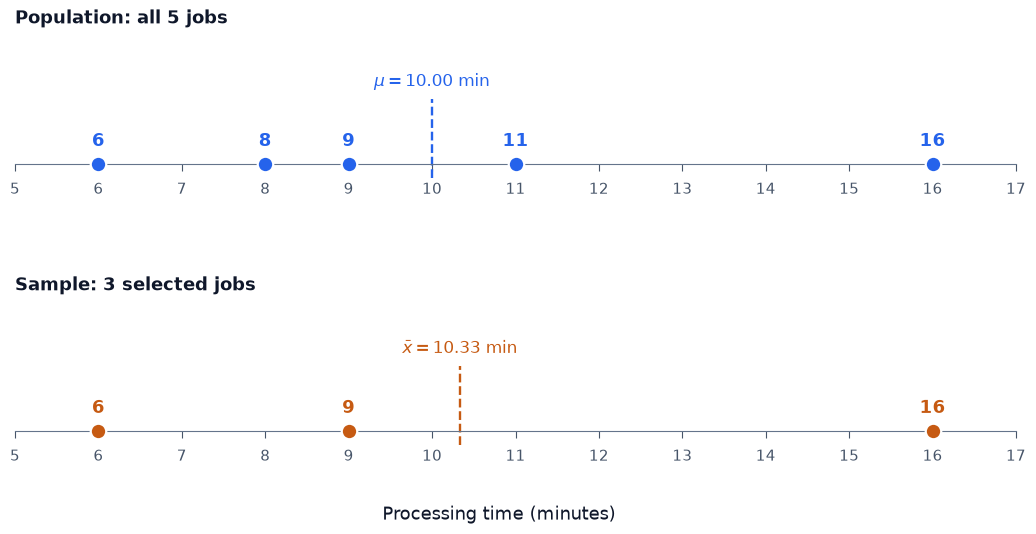

In [2]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titleweight": "bold",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})
population_color = "#2563eb"
sample_color = "#c65a12"
ink = "#0f172a"

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5))
panels = [
    (axes[0], population, mu, population_color,
     f"Population: all {N} jobs", rf"$\mu = {mu:.2f}$ min"),
    (axes[1], sample, x_bar, sample_color,
     f"Sample: {n} selected jobs", rf"$\bar{{x}} = {x_bar:.2f}$ min"),
]

for ax, values, center, color, title, mean_label in panels:
    ax.scatter(values, np.zeros(len(values)), s=125, color=color,
               edgecolors="white", linewidths=1.6, zorder=4)
    for value in values:
        ax.annotate(f"{value:g}", (value, 0), xytext=(0, 13),
                    textcoords="offset points", ha="center",
                    fontsize=13, fontweight="bold", color=color)
    ax.vlines(center, -0.10, 0.48, color=color,
              linestyle="--", linewidth=1.7, zorder=2)
    ax.text(center, 0.57, mean_label, ha="center", color=color, fontsize=12)
    ax.set_xlim(5, 17)
    ax.set_ylim(-0.40, 0.95)
    ax.set_xticks(np.arange(5, 18))
    ax.set_yticks([])
    for side in ("left", "right", "top"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_position(("data", 0))
    ax.spines["bottom"].set_color("#64748b")
    ax.tick_params(axis="x", colors="#475569", length=5, pad=8)
    ax.set_title(title, loc="left", color=ink, pad=8)

fig.supxlabel("Processing time (minutes)", y=0.03, color=ink)
fig.subplots_adjust(left=0.06, right=0.97, top=0.92, bottom=0.10, hspace=0.45)
plt.show()

## 4. Compare the means

The population mean uses all five observations:

$$\mu=\frac{6+8+9+11+16}{5}=\frac{50}{5}=10\text{ minutes}.$$

The sample mean uses only the three selected observations:

$$\bar{x}=\frac{6+9+16}{3}=\frac{31}{3}\approx10.333\text{ minutes}.$$

For this sample, the **estimation error** is

$$\bar{x}-\mu=\frac{31}{3}-10=\frac{1}{3}\approx+0.333\text{ minutes}.$$

The sample overestimates the population mean by about one-third of a minute.
One sample's error is not the same as an estimator's **bias**: bias concerns
the average error across repeated samples under a specified sampling method.

## 5. Compare variance and standard deviation

First subtract each group's **own mean**, then square those deviations.

In [3]:
def show_deviations(values, center, heading):
    rows = [
        "| Observation (min) | Deviation from mean (min) | Squared deviation (min²) |",
        "| ---: | ---: | ---: |",
    ]
    for value in values:
        deviation = value - center
        rows.append(f"| {value:g} | {deviation:+.4f} | {deviation**2:.4f} |")
    sum_of_squares = np.sum((values - center)**2)
    rows.append(f"| **Total squared deviations** | | **{sum_of_squares:.4f}** |")
    display(Markdown(f"**{heading}**\n\n" + "\n".join(rows)))

show_deviations(population, mu, f"Population: subtract μ = {mu:.4f}")
show_deviations(sample, x_bar, f"Sample: subtract x̄ = {x_bar:.4f}")

**Population: subtract μ = 10.0000**

| Observation (min) | Deviation from mean (min) | Squared deviation (min²) |
| ---: | ---: | ---: |
| 6 | -4.0000 | 16.0000 |
| 8 | -2.0000 | 4.0000 |
| 9 | -1.0000 | 1.0000 |
| 11 | +1.0000 | 1.0000 |
| 16 | +6.0000 | 36.0000 |
| **Total squared deviations** | | **58.0000** |

**Sample: subtract x̄ = 10.3333**

| Observation (min) | Deviation from mean (min) | Squared deviation (min²) |
| ---: | ---: | ---: |
| 6 | -4.3333 | 18.7778 |
| 9 | -1.3333 | 1.7778 |
| 16 | +5.6667 | 32.1111 |
| **Total squared deviations** | | **52.6667** |

### Population calculation

$$\sum_{j=1}^{N}(y_j-\mu)^2=16+4+1+1+36=58.$$

$$\sigma^2=\frac{58}{5}=11.6\text{ min}^2,
\qquad\sigma=\sqrt{11.6}\approx3.406\text{ min}.$$

### Sample calculation

Using the exact sample mean $31/3$ avoids rounding during the calculation:

$$\sum_{i=1}^{n}(x_i-\bar{x})^2
=\left(-\frac{13}{3}\right)^2+\left(-\frac{4}{3}\right)^2
+\left(\frac{17}{3}\right)^2=\frac{158}{3}.$$

$$s^2=\frac{158/3}{3-1}=\frac{79}{3}\approx26.333\text{ min}^2,
\qquad s=\sqrt{79/3}\approx5.132\text{ min}.$$

For this chosen sample, the estimated standard deviation is larger than the
population standard deviation. That is a result for this particular sample,
not a rule that sample standard deviations must always be larger.

In [4]:
rows = [
    "| Quantity | Population parameter | Sample statistic | Sample minus population |",
    "| :--- | ---: | ---: | ---: |",
    f"| Mean (min) | {mu:.4f} | {x_bar:.4f} | {x_bar - mu:+.4f} |",
    f"| Variance (min²) | {population_variance:.4f} | {sample_variance:.4f} | {sample_variance - population_variance:+.4f} |",
    f"| Standard deviation (min) | {sigma:.4f} | {s:.4f} | {s - sigma:+.4f} |",
]
display(Markdown("\n".join(rows)))

| Quantity | Population parameter | Sample statistic | Sample minus population |
| :--- | ---: | ---: | ---: |
| Mean (min) | 10.0000 | 10.3333 | +0.3333 |
| Variance (min²) | 11.6000 | 26.3333 | +14.7333 |
| Standard deviation (min) | 3.4059 | 5.1316 | +1.7257 |

## 6. Why does the sample formula use n − 1?

After calculating the sample mean, the deviations must sum to zero:

$$\sum_{i=1}^{n}(x_i-\bar{x})=0.$$

Once $n-1$ deviations are specified, the final deviation is determined. We say
that the deviations have **$n-1$ degrees of freedom**.

For independent observations drawn from the same distribution with finite
variance, dividing by $n-1$ makes $s^2$ an unbiased estimator of that distribution's
variance. This is a property across repeated samples; it does not guarantee
that one sample's estimate is close. Taking a square root does **not** generally
make $s$ an unbiased estimator of the standard deviation.

In NumPy, `ddof` means *delta degrees of freedom*: the divisor is the number
of observations minus `ddof`. Use `ddof=0` for the variance of the complete
population and `ddof=1` for the usual sample variance.

**Optional finite-population detail.** Our five jobs are a fixed finite population.
Under simple random sampling *without replacement*, $s^2$ is unbiased for
$S^2=\sum(y_j-\mu)^2/(N-1)$, rather than for the descriptive variance
$\sigma^2=\sum(y_j-\mu)^2/N$ used above. The adjusted estimator
$(N-1)s^2/N$ is unbiased for that descriptive variance. Our initial sample was
chosen by hand, so these repeated-random-sampling guarantees do not apply to
its selection method.

## 7. What if we selected a different sample?

There are $\binom{5}{3}=10$ distinct groups of three jobs that can be selected
without replacement. Below we enumerate **every** group and calculate its mean.
This is an exact enumeration, not a simulation.

If each group were equally likely (simple random sampling), these means would
form the exact sampling distribution of $\bar{x}$. The population mean stays
fixed at 10 minutes.

In [5]:
all_samples = np.array(list(combinations(population, n)))
all_sample_means = all_samples.mean(axis=1)
selected_row = next(
    i for i, values in enumerate(all_samples)
    if np.array_equal(values, sample)
)

rows = ["| Possible sample (minutes) | Sample mean (minutes) |",
        "| :--- | ---: |"]
for i, (values, mean) in enumerate(zip(all_samples, all_sample_means)):
    label = ", ".join(f"{v:g}" for v in values)
    if i == selected_row:
        label += " **← our sample**"
    rows.append(f"| ({label}) | {mean:.4f} |")
display(Markdown("\n".join(rows)))
print(f"Mean of all {len(all_sample_means)} sample means: {all_sample_means.mean():.4f} minutes")
print(f"Population mean: {mu:.4f} minutes")

| Possible sample (minutes) | Sample mean (minutes) |
| :--- | ---: |
| (6, 8, 9) | 7.6667 |
| (6, 8, 11) | 8.3333 |
| (6, 8, 16) | 10.0000 |
| (6, 9, 11) | 8.6667 |
| (6, 9, 16 **← our sample**) | 10.3333 |
| (6, 11, 16) | 11.0000 |
| (8, 9, 11) | 9.3333 |
| (8, 9, 16) | 11.0000 |
| (8, 11, 16) | 11.6667 |
| (9, 11, 16) | 12.0000 |

Mean of all 10 sample means: 10.0000 minutes
Population mean: 10.0000 minutes


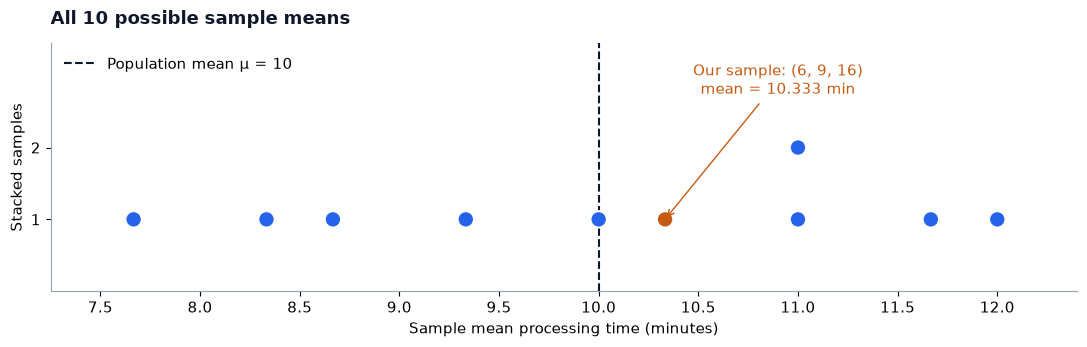

In [6]:
# Stack dots when two different samples produce the same mean.
stacks = Counter()
stack_heights = []
for mean in all_sample_means:
    key = round(float(mean), 10)
    stacks[key] += 1
    stack_heights.append(stacks[key])
stack_heights = np.array(stack_heights)
colors = [sample_color if i == selected_row else population_color
          for i in range(len(all_sample_means))]

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.scatter(all_sample_means, stack_heights, c=colors, s=140,
           edgecolors="white", linewidths=1.5, zorder=3)
ax.axvline(mu, color=ink, linestyle="--", linewidth=1.5,
           label=f"Population mean μ = {mu:g}")
sample_label = ", ".join(f"{v:g}" for v in sample)
ax.annotate(f"Our sample: ({sample_label})\nmean = {x_bar:.3f} min",
            (all_sample_means[selected_row], stack_heights[selected_row]),
            xytext=(10.9, 2.75), color=sample_color, fontsize=11,
            arrowprops={"arrowstyle": "->", "color": sample_color},
            ha="center")
ax.set_xlim(7.25, 12.4)
ax.set_ylim(0, 3.45)
ax.set_xticks(np.arange(7.5, 12.5, 0.5))
ax.set_yticks([1, 2])
ax.set_ylabel("Stacked samples")
ax.set_xlabel("Sample mean processing time (minutes)")
ax.set_title("All 10 possible sample means", loc="left", color=ink, pad=14)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#94a3b8")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
plt.show()

Each dot in this last plot represents a **sample of three jobs**, not an
individual processing time. Two samples have a mean of 11 minutes, so those
dots are stacked. The average of all ten equally weighted sample means is
exactly 10 minutes, the population mean. This illustrates why the sample mean
is unbiased under simple random sampling, even though any particular sample
mean can be too high or too low.

## 8. Experiment with a larger population

The three-job example shows the arithmetic, but one sample cannot establish
whether an estimator tends to be too high or too low. We will now study
**repeated samples** from a larger, fully known population.

Generate **20,000 synthetic processing times** from a gamma distribution. These
are positive, mildly right-skewed values: many jobs finish near the center, with
some longer jobs. The exact mean and variance of the generated population are
calculated from all 20,000 values; we use those fixed values as the truth.
The data are simulated for teaching, not measurements from a real service.

For these experiments, draw independently **with replacement** from the larger
population. Each draw has the same distribution, and selecting a job does not
remove it from the next draw. This differs from the earlier enumeration without
replacement and makes the usual unbiased-variance result apply to our target
$\sigma^2=\sum(y_j-\mu)^2/N$ exactly.

The code keeps the original five-job population intact. Change the parameters
below to explore the larger experiment, then rerun this cell and the cells below it.

In [7]:
# Experiment controls. Random seeds make the saved results reproducible.
population_seed = 20261001
illustration_seed = 20261002
simulation_seed = 20261003
large_N = 20_000
focus_n = 5
repetitions = 50_000
sample_sizes = np.unique([2, 3, 5, 10, 30, 100, focus_n])

if focus_n < 2 or repetitions < 10 or large_N < 2:
    raise ValueError("Use focus_n >= 2, repetitions >= 10, and large_N >= 2.")
if np.any(sample_sizes < 2):
    raise ValueError("Each sample size must be at least 2 for sample variance.")

data_rng = np.random.default_rng(population_seed)
large_population = data_rng.gamma(shape=4.0, scale=2.5, size=large_N)
large_mu = large_population.mean()
large_variance = large_population.var(ddof=0)

illustration_rng = np.random.default_rng(illustration_seed)
focus_sample = illustration_rng.choice(large_population, size=focus_n, replace=True)
focus_mean = focus_sample.mean()

print(f"Known population size N = {large_N:,}")
print(f"Known population mean = {large_mu:.6f} min")
print(f"Known population variance = {large_variance:.6f} min²")
print(f"One illustrative sample (n = {focus_n}): {np.round(focus_sample, 3)}")
print(f"Illustrative sample mean = {focus_mean:.6f} min")
print(f"Repeated samples per size = {repetitions:,}")

Known population size N = 20,000
Known population mean = 10.010915 min
Known population variance = 25.079723 min²
One illustrative sample (n = 5): [10.353  4.67  18.882 10.234  9.403]
Illustrative sample mean = 10.708704 min
Repeated samples per size = 50,000


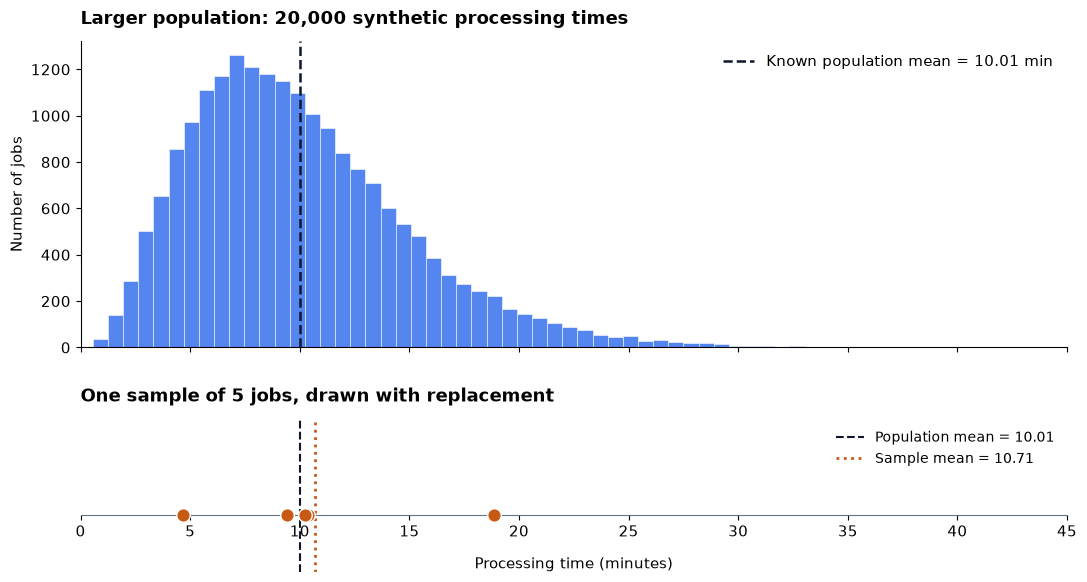

In [8]:
known_color = "#14806d"
naive_color = "#c65a12"
corrected_color = "#2563eb"

fig, (ax_pop, ax_sample) = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True,
    gridspec_kw={"height_ratios": [2.0, 1.0]},
)
ax_pop.hist(large_population, bins=60, color=population_color,
            alpha=0.78, edgecolor="white", linewidth=0.5)
ax_pop.axvline(large_mu, color=ink, linestyle="--", linewidth=1.8,
               label=f"Known population mean = {large_mu:.2f} min")
ax_pop.set_title(f"Larger population: {large_N:,} synthetic processing times",
                 loc="left", pad=12)
ax_pop.set_ylabel("Number of jobs")
ax_pop.legend(frameon=False, loc="upper right")
ax_pop.spines[["top", "right"]].set_visible(False)

ax_sample.scatter(focus_sample, np.zeros(focus_n), s=95,
                  color=sample_color, edgecolors="white", zorder=4)
ax_sample.axvline(large_mu, color=ink, linestyle="--", linewidth=1.5,
                  label=f"Population mean = {large_mu:.2f}")
ax_sample.axvline(focus_mean, color=sample_color, linestyle=":", linewidth=2,
                  label=f"Sample mean = {focus_mean:.2f}")
ax_sample.spines["bottom"].set_position(("data", 0))
ax_sample.spines["bottom"].set_color("#64748b")
ax_sample.spines[["left", "right", "top"]].set_visible(False)
ax_sample.set_yticks([])
ax_sample.set_ylim(-0.35, 0.60)
ax_sample.set_title(f"One sample of {focus_n} jobs, drawn with replacement",
                    loc="left", pad=12)
ax_sample.legend(frameon=False, loc="upper right", fontsize=10)
ax_sample.set_xlim(0, np.ceil(large_population.max() / 5) * 5)
ax_sample.set_xlabel("Processing time (minutes)", labelpad=12)
fig.tight_layout(h_pad=2.0)
plt.show()

### Why estimating the mean reduces the squared deviations

The sample mean is the center that minimizes the sum of squared distances to
the sample's observations. It is fitted to those same observations. Subtracting
it makes the squared deviations smaller than subtracting the true population
mean, except when the two means happen to match.

For **every** sample, this exact identity holds:

$$
\underbrace{\sum_{i=1}^{n}(x_i-\mu)^2}_{\text{distances from the true mean}}
=
\underbrace{\sum_{i=1}^{n}(x_i-\bar{x})^2}_{\text{distances from the fitted mean}}
+\underbrace{n(\bar{x}-\mu)^2}_{\text{reduction from fitting the mean}}.
$$

The final term is nonnegative. The next cell checks the identity for the
illustrative sample and compares three variance calculations.

In [9]:
ss_true_mean = np.sum((focus_sample - large_mu)**2)
ss_fitted_mean = np.sum((focus_sample - focus_mean)**2)
reduction = focus_n * (focus_mean - large_mu)**2

display(Markdown(
    f"Squared deviations from the **true mean**: **{ss_true_mean:.6f} min²**.\n\n"
    f"Squared deviations from the **sample mean**: **{ss_fitted_mean:.6f} min²**.\n\n"
    f"Reduction from fitting the mean: **{reduction:.6f} min²**.\n\n"
    f"Identity: {ss_true_mean:.6f} = {ss_fitted_mean:.6f} + {reduction:.6f}."
))

rows = [
    "| Center and divisor | Variance for this one sample (min²) |",
    "| :--- | ---: |",
    f"| Known population mean; divide by n | {ss_true_mean / focus_n:.6f} |",
    f"| Estimated sample mean; divide by n | {ss_fitted_mean / focus_n:.6f} |",
    f"| Estimated sample mean; divide by n − 1 | {ss_fitted_mean / (focus_n - 1):.6f} |",
    f"| **Actual population variance** | **{large_variance:.6f}** |",
]
display(Markdown("\n".join(rows)))
print("One draw can overestimate or underestimate. We need repeated draws to study bias.")

Squared deviations from the **true mean**: **107.762146 min²**.

Squared deviations from the **sample mean**: **105.327596 min²**.

Reduction from fitting the mean: **2.434550 min²**.

Identity: 107.762146 = 105.327596 + 2.434550.

| Center and divisor | Variance for this one sample (min²) |
| :--- | ---: |
| Known population mean; divide by n | 21.552429 |
| Estimated sample mean; divide by n | 21.065519 |
| Estimated sample mean; divide by n − 1 | 26.331899 |
| **Actual population variance** | **25.079723** |

One draw can overestimate or underestimate. We need repeated draws to study bias.


## 9. Repeat the sampling: compare three estimators

The larger population stays fixed. Each repetition creates a fresh independent
sample and calculates these three estimators:

| Center and divisor | Formula | Expected value over repeated independent samples |
| :--- | :--- | :--- |
| Known population mean; divide by $n$ | $\displaystyle v_{\mu}=\frac{1}{n}\sum(X_i-\mu)^2$ | $\sigma^2$ |
| Estimated sample mean; divide by $n$ | $\displaystyle v_n=\frac{1}{n}\sum(X_i-\bar X)^2$ | $\displaystyle\frac{n-1}{n}\sigma^2$ |
| Estimated sample mean; divide by $n-1$ | $\displaystyle s^2=\frac{1}{n-1}\sum(X_i-\bar X)^2$ | $\sigma^2$ |

The first row is a teaching benchmark: it requires knowing the population mean,
which we usually do not know in a real study. The second and third rows use the
same observations and the same fitted mean; only the divisor changes.

**The reason for exactly $n-1$.** Under independent draws with the same finite
variance, $\mathrm{Var}(\bar X)=\sigma^2/n$. Taking expectations in the squared-distance
identity gives:

$$
E\left[\sum_{i=1}^{n}(X_i-\bar X)^2\right]
=n\sigma^2-nE[(\bar X-\mu)^2]
=n\sigma^2-n\frac{\sigma^2}{n}
=(n-1)\sigma^2.
$$

Dividing by $n-1$ therefore gives $E[s^2]=\sigma^2$. Dividing by $n$ instead
gives $E[v_n]=(1-1/n)\sigma^2$. For $n=5$, that is only **80% of the true variance**
on average: an underestimate of 20%.

The experiment below uses 50,000 repetitions per sample size by default. Its
averages should be near these predictions, but finite simulations still have
random variation. The expected-value identities hold exactly under the stated
sampling assumptions; a finite simulation only illustrates them.

In [10]:
simulation_results = {}
simulation_summary = []

for size in sample_sizes:
    size = int(size)
    # A separate reproducible stream for each size keeps comparisons stable
    # when other sizes are added or removed from sample_sizes.
    sampling_rng = np.random.default_rng(np.random.SeedSequence([simulation_seed, size]))
    draws = sampling_rng.choice(large_population, size=(repetitions, size), replace=True)
    fitted_means = draws.mean(axis=1)
    residual_ss = np.sum((draws - fitted_means[:, None])**2, axis=1)

    estimates = {
        "known_mean": np.mean((draws - large_mu)**2, axis=1),
        "divide_n": residual_ss / size,
        "divide_n_minus_1": residual_ss / (size - 1),
    }
    simulation_results[size] = estimates
    simulation_summary.append({
        "n": size,
        "known_mean": estimates["known_mean"].mean(),
        "divide_n": estimates["divide_n"].mean(),
        "divide_n_minus_1": estimates["divide_n_minus_1"].mean(),
        "expected_divide_n": (size - 1) / size * large_variance,
    })
    del draws

rows = [
    "| Sample size n | Mean estimate: known μ, divisor n | Mean estimate: fitted mean, divisor n | Mean estimate: fitted mean, divisor n − 1 | Theory for divisor n | True population variance |",
    "| ---: | ---: | ---: | ---: | ---: | ---: |",
]
for result in simulation_summary:
    rows.append(
        f"| {result['n']} | {result['known_mean']:.4f} | {result['divide_n']:.4f} "
        f"| {result['divide_n_minus_1']:.4f} | {result['expected_divide_n']:.4f} "
        f"| {large_variance:.4f} |"
    )
display(Markdown("**Averages across repeated samples; all variances are in minutes squared.**\n\n" + "\n".join(rows)))

**Averages across repeated samples; all variances are in minutes squared.**

| Sample size n | Mean estimate: known μ, divisor n | Mean estimate: fitted mean, divisor n | Mean estimate: fitted mean, divisor n − 1 | Theory for divisor n | True population variance |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 2 | 25.0259 | 12.5193 | 25.0386 | 12.5399 | 25.0797 |
| 3 | 25.2415 | 16.8660 | 25.2991 | 16.7198 | 25.0797 |
| 5 | 24.9629 | 19.9561 | 24.9452 | 20.0638 | 25.0797 |
| 10 | 25.0265 | 22.5294 | 25.0327 | 22.5718 | 25.0797 |
| 30 | 25.0944 | 24.2544 | 25.0907 | 24.2437 | 25.0797 |
| 100 | 25.0798 | 24.8296 | 25.0805 | 24.8289 | 25.0797 |

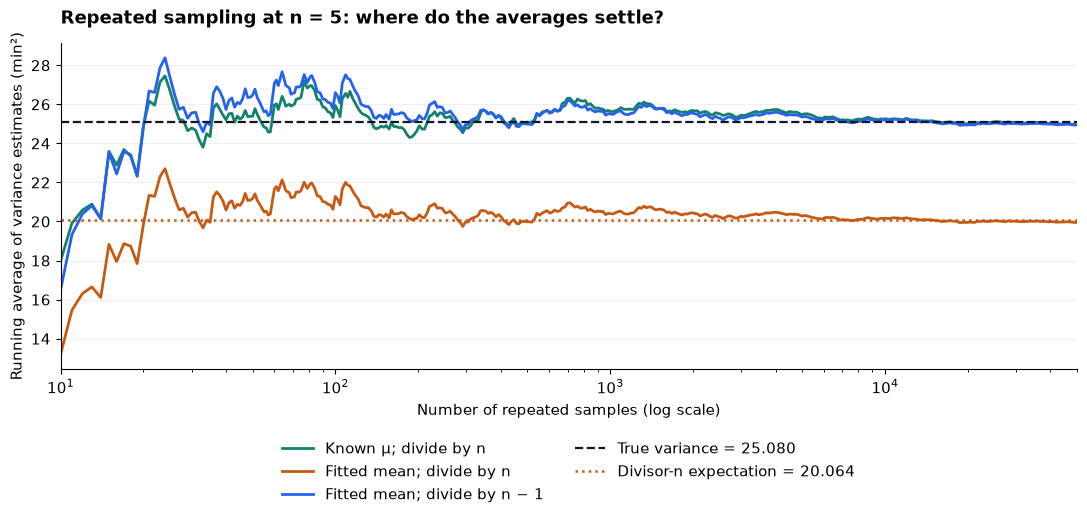

In [11]:
focus_results = simulation_results[focus_n]
checkpoints = np.unique(np.geomspace(10, repetitions, 400).astype(int))
styles = [
    ("known_mean", known_color, "Known μ; divide by n"),
    ("divide_n", naive_color, "Fitted mean; divide by n"),
    ("divide_n_minus_1", corrected_color, "Fitted mean; divide by n − 1"),
]

fig, ax = plt.subplots(figsize=(11, 5.5))
for key, color, label in styles:
    running_average = np.cumsum(focus_results[key]) / np.arange(1, repetitions + 1)
    ax.plot(checkpoints, running_average[checkpoints - 1], color=color,
            linewidth=2, label=label)

ax.axhline(large_variance, color=ink, linestyle="--", linewidth=1.6,
           label=f"True variance = {large_variance:.3f}")
biased_target = (focus_n - 1) / focus_n * large_variance
ax.axhline(biased_target, color=naive_color, linestyle=":", linewidth=1.8,
           label=f"Divisor-n expectation = {biased_target:.3f}")
ax.set_xscale("log")
ax.set_xlim(10, repetitions)
ax.set_xlabel("Number of repeated samples (log scale)")
ax.set_ylabel("Running average of variance estimates (min²)")
ax.set_title(f"Repeated sampling at n = {focus_n}: where do the averages settle?",
             loc="left", pad=14)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
fig.tight_layout()
plt.show()

In [12]:
focus_expected = {
    "known_mean": large_variance,
    "divide_n": (focus_n - 1) / focus_n * large_variance,
    "divide_n_minus_1": large_variance,
}
rows = [
    "| Calculation | Simulated average | Expected average | Monte Carlo standard error of simulated average |",
    "| :--- | ---: | ---: | ---: |",
]
for key, color, label in styles:
    values = focus_results[key]
    mc_se = values.std(ddof=1) / np.sqrt(repetitions)
    rows.append(f"| {label} | {values.mean():.5f} | {focus_expected[key]:.5f} | {mc_se:.5f} |")
display(Markdown("\n".join(rows)))
display(Markdown(
    f"For **n = {focus_n}**, dividing by n has theoretical relative bias "
    f"**−{100 / focus_n:.2f}%**. Increasing the number of repetitions makes that "
    "bias easier to see; it does not remove it. Increasing the size of each "
    "sample reduces the relative bias. The Monte Carlo standard error describes "
    "simulation noise in the reported average, not the uncertainty of one sample's estimate."
))

| Calculation | Simulated average | Expected average | Monte Carlo standard error of simulated average |
| :--- | ---: | ---: | ---: |
| Known μ; divide by n | 24.96286 | 25.07972 | 0.09182 |
| Fitted mean; divide by n | 19.95613 | 20.06378 | 0.07890 |
| Fitted mean; divide by n − 1 | 24.94517 | 25.07972 | 0.09863 |

For **n = 5**, dividing by n has theoretical relative bias **−20.00%**. Increasing the number of repetitions makes that bias easier to see; it does not remove it. Increasing the size of each sample reduces the relative bias. The Monte Carlo standard error describes simulation noise in the reported average, not the uncertainty of one sample's estimate.

## 10. Change the sample size

The relative bias from dividing by $n$ is:

$$
\frac{E[v_n]-\sigma^2}{\sigma^2}=-\frac{1}{n}.
$$

It is −50% for $n=2$, −20% for $n=5$, −10% for $n=10$, and −1% for $n=100$.
The $n-1$ correction matters most for small samples, although it remains the
usual choice for unbiased variance estimation at larger sizes.

The next plot divides each simulated average by the true variance. A ratio
of **1** means the average estimate matches the target. Compare the simulation
points with the theoretical curves.

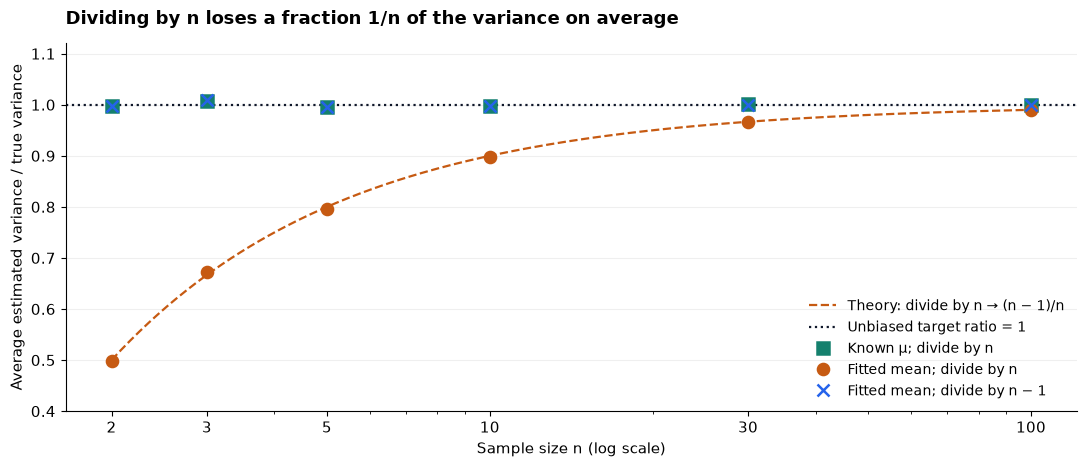

In [13]:
sizes = np.array([result["n"] for result in simulation_summary])
size_grid = np.geomspace(sizes.min(), sizes.max(), 300)
fig, ax = plt.subplots(figsize=(11, 4.8))

ax.plot(size_grid, (size_grid - 1) / size_grid, color=naive_color,
        linestyle="--", linewidth=1.6, label="Theory: divide by n → (n − 1)/n")
ax.axhline(1, color=ink, linestyle=":", linewidth=1.6,
           label="Unbiased target ratio = 1")
for key, color, label in styles:
    ratios = [result[key] / large_variance for result in simulation_summary]
    marker = {"known_mean": "s", "divide_n": "o", "divide_n_minus_1": "x"}[key]
    ax.plot(sizes, ratios, color=color, marker=marker, linestyle="none",
            markersize=8, markeredgewidth=1.8, label=label)

ax.set_xscale("log")
ax.set_xticks(sizes, labels=[str(size) for size in sizes])
ax.set_xlabel("Sample size n (log scale)")
ax.set_ylabel("Average estimated variance / true variance")
ax.set_ylim(0.40, 1.12)
ax.set_title("Dividing by n loses a fraction 1/n of the variance on average",
             loc="left", pad=14)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False, loc="lower right", fontsize=10)
fig.tight_layout()
plt.show()

**What these experiments establish:** fitting the sample mean removes, on
average, one population variance's worth of squared deviation. That leaves
$(n-1)\sigma^2$ in the numerator on average, which explains the divisor $n-1$.

**What unbiased does not mean:** $s^2$ need not be closer to $\sigma^2$ for every
sample. Unbiasedness is an average-over-samples property, not a guarantee about
one draw or a claim that an estimator minimizes mean squared error. Also,
$s=\sqrt{s^2}$ is generally not an unbiased estimator of $\sigma$.

**Try these changes in the experiment-controls cell:**

1. Change `repetitions` to `100`, then `1_000`, then `50_000`. Notice that more
   repetitions reduce simulation noise while the divisor-$n$ average still
   falls below the target.
2. Change `focus_n` from `5` to `3` or `30`. Predict the relative bias using
   $-1/n$ before inspecting the updated outputs.
3. Change `simulation_seed` and rerun. Individual results change, but the
   averages should remain near the same theoretical predictions.
4. Change the gamma shape or scale in the data-generation line. The known
   population moments and plots update; the independent-sampling argument
   does not require normally distributed processing times.

Keep `replace=True` for this experiment. Sampling without replacement changes
the finite-population expectation, as explained in section 6. The formulas
also assume independent observations; correlated data need a different analysis.

## 11. What to remember

- A **parameter** describes a population; a **statistic** is calculated from a sample.
- A statistic becomes an **estimate** when it is used to infer a population parameter.
- Here, $\mu=10$ minutes and $\sigma\approx3.406$ minutes describe all five jobs.
- For the sample $(6,9,16)$, $\bar{x}\approx10.333$ minutes and $s\approx5.132$ minutes.
- A different sample can produce different estimates while the population stays fixed.
- A suitable sampling method matters. Choosing convenient observations alone does
  not guarantee that a sample represents the population.

- Estimating the mean leaves $(n-1)\sigma^2$ in the squared-deviation sum on average; dividing by $n-1$ corrects the variance bias under independent sampling.

**Try it:** replace `sample_indices = np.array([0, 2, 4])` with
`sample_indices = np.array([0, 1, 2])` and rerun the code cells. These positions
select 6, 8, and 9 minutes. Predict whether the mean and standard deviation
will increase or decrease. Code outputs update automatically; the written
worked calculations above continue to describe the original sample $(6,9,16)$.